# Loan Approval Prediction
**Author:** Anesu Rirwa

**Question:** Can we predict whether a home-loan application will be approved from the details on the application form, and is a machine learning model actually better than a simple rule?

**Data:** Loan Prediction dataset (Dream Housing Finance, public on Kaggle). `loan-train.csv` has 614 applications with the outcome (`Loan_Status`); `loan-test.csv` has 367 applications without the outcome, used only to produce predictions.

**Approach**
1. Explore and clean the data.
2. Set baselines first: always predicting "approved", and a one-line rule on credit history.
3. Compare logistic regression, random forest and XGBoost using 5-fold cross-validation on the training portion.
4. Evaluate the chosen model once on a held-out test split.
5. Explain what drives the predictions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.width", 140)

## 1. Load and inspect the data

In [2]:
train_raw = pd.read_csv("loan-train.csv")
test_raw = pd.read_csv("loan-test.csv")
print("Train:", train_raw.shape, " Test (no labels):", test_raw.shape)
train_raw.head()

Train: (614, 13)  Test (no labels): (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("Missing values (% of rows):")
print((train_raw.isna().mean() * 100).round(1).sort_values(ascending=False))
print()
print("Outcome balance:")
print(train_raw["Loan_Status"].value_counts(normalize=True).round(3))

Missing values (% of rows):
Credit_History       8.1
Self_Employed        5.2
LoanAmount           3.6
Dependents           2.4
Loan_Amount_Term     2.3
Gender               2.1
Married              0.5
Education            0.0
Loan_ID              0.0
CoapplicantIncome    0.0
ApplicantIncome      0.0
Property_Area        0.0
Loan_Status          0.0
dtype: float64

Outcome balance:
Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64


**Observations**
- About 69% of applications are approved, so a model must beat **69% accuracy** just to be better than always saying "yes".
- `Credit_History` is missing for about 8% of applicants. Missing values are filled **inside the modelling pipeline**, using only the training data, so no information from the test data leaks into training.

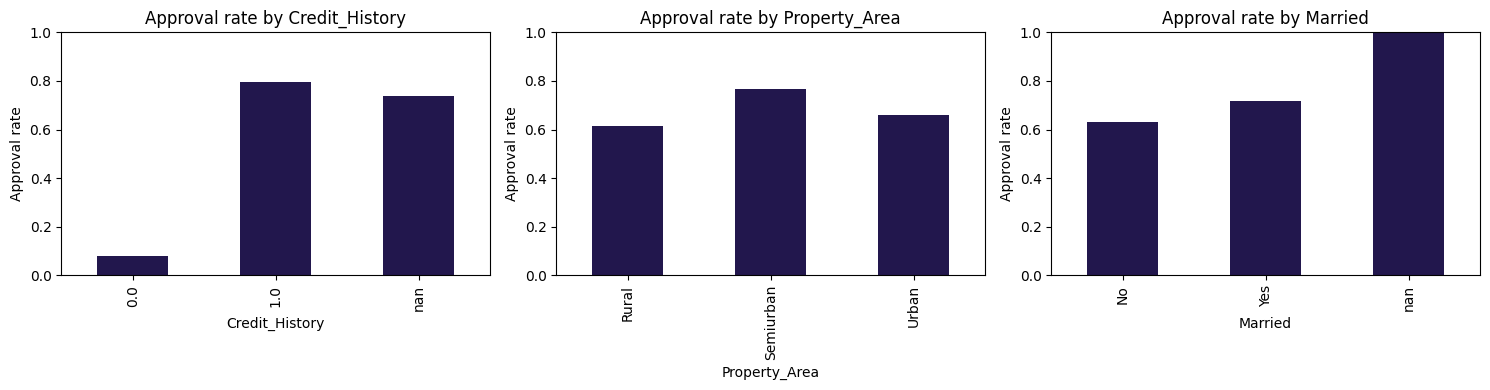

Credit_History
0.0    0.079
1.0    0.796
NaN    0.740
Name: Loan_Status, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Credit_History", "Property_Area", "Married"]):
    (train_raw.groupby(col, dropna=False)["Loan_Status"]
              .apply(lambda s: (s == "Y").mean())
              .plot(kind="bar", ax=ax, color="#22174D"))
    ax.set_title(f"Approval rate by {col}"); ax.set_ylabel("Approval rate"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

print(train_raw.groupby("Credit_History", dropna=False)["Loan_Status"]
               .apply(lambda s: round((s == "Y").mean(), 3)))

**Observation:** credit history dominates. Applicants with a good credit history (1.0) are approved about 80% of the time; applicants without one are almost always rejected. Any model will lean heavily on this one column, so the real question is whether the other columns add anything.

## 2. Feature engineering

In [5]:
def add_features(df):
    df = df.copy()
    df["Dependents"] = df["Dependents"].replace("3+", "3")
    df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
    # Loan size relative to household income: a rough affordability measure
    df["LoanToIncome"] = df["LoanAmount"] / df["TotalIncome"]
    # Approximate monthly repayment (LoanAmount is in thousands, term in months)
    df["MonthlyPayment"] = df["LoanAmount"] * 1000 / df["Loan_Amount_Term"]
    return df

train = add_features(train_raw)
test_unlabelled = add_features(test_raw)

y = (train["Loan_Status"] == "Y").astype(int)
X = train.drop(columns=["Loan_ID", "Loan_Status"])

categorical = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Credit_History"]
numeric = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
           "TotalIncome", "LoanToIncome", "MonthlyPayment"]

# Credit_History is 1/0/missing, so treat it as a category (missing becomes its own group)
for df in (X, test_unlabelled):
    df["Credit_History"] = df["Credit_History"].map({1.0: "good", 0.0: "bad"})

## 3. Train/test split and preprocessing pipeline
20% of the labelled data is locked away as a test set and touched only once, at the end. Cross-validation on the remaining 80% is used to compare models.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),      # incomes and loan sizes are heavily right-skewed
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric),
    ("cat", categorical_pipe, categorical),
])

Train: (491, 14)  Test: (123, 14)


## 4. Baselines and model comparison (5-fold cross-validation)

In [7]:
class CreditHistoryRule:
    """Approve if credit history is good or unknown; reject if it is 0."""
    def fit(self, X, y): return self
    def predict(self, X): return (X["Credit_History"] != "bad").astype(int).values

models = {
    "Always approve (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000, C=0.5),
    "Random forest": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5,
                                            random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
# Rule baseline: evaluate on the same folds
rule = CreditHistoryRule()
rule_acc, rule_f1 = [], []
for tr, va in cv.split(X_train, y_train):
    p = rule.predict(X_train.iloc[va]); rule_acc.append(accuracy_score(y_train.iloc[va], p)); rule_f1.append(f1_score(y_train.iloc[va], p))
rows.append({"Model": "Credit-history rule (baseline)", "Accuracy": np.mean(rule_acc), "F1": np.mean(rule_f1), "ROC-AUC": np.nan})

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    rows.append({"Model": name, "Accuracy": scores["test_accuracy"].mean(),
                 "F1": scores["test_f1"].mean(), "ROC-AUC": scores["test_roc_auc"].mean()})

cv_results = pd.DataFrame(rows).set_index("Model").round(3)
cv_results

,Accuracy,F1,ROC-AUC
Model,,,
Credit-history rule (baseline),0.798,0.870,NaN
Always approve (baseline),0.686,0.814,0.500
Logistic regression,0.790,0.864,0.731
Random forest,0.798,0.870,0.762
XGBoost,0.786,0.858,0.766


**Reading the comparison**
- All three ML models land very close to the one-line credit-history rule. On this dataset, the extra columns add little beyond credit history.
- ROC-AUC (how well the model *ranks* applicants by risk) is where models add value over the rule: a lender can use the probability to prioritise manual reviews rather than just getting a yes/no.
- Logistic regression is chosen as the final model. Its accuracy is within about one point of the tree models (their ROC-AUC is a few points higher), and it is simpler and its coefficients are easy to explain to a credit committee.

## 5. Final evaluation on the held-out test set

                     Accuracy  Precision  Recall  ROC-AUC
Always approve          0.691      0.691   1.000    0.500
Credit-history rule     0.854      0.832   0.988      NaN
Logistic regression     0.854      0.832   0.988    0.862

              precision    recall  f1-score   support

    Rejected      0.955     0.553     0.700        38
    Approved      0.832     0.988     0.903        85

    accuracy                          0.854       123
   macro avg      0.893     0.770     0.802       123
weighted avg      0.870     0.854     0.840       123



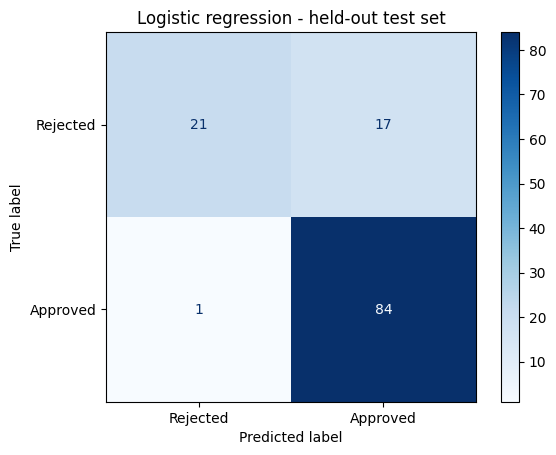

In [8]:
final = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000, C=0.5))])
final.fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

rule_pred = CreditHistoryRule().predict(X_test)
summary = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, np.ones_like(y_test)), accuracy_score(y_test, rule_pred), accuracy_score(y_test, pred)],
    "Precision": [precision_score(y_test, np.ones_like(y_test)), precision_score(y_test, rule_pred), precision_score(y_test, pred)],
    "Recall": [recall_score(y_test, np.ones_like(y_test)), recall_score(y_test, rule_pred), recall_score(y_test, pred)],
    "ROC-AUC": [0.5, np.nan, roc_auc_score(y_test, proba)],
}, index=["Always approve", "Credit-history rule", "Logistic regression"]).round(3)
print(summary)
print()
print(classification_report(y_test, pred, target_names=["Rejected", "Approved"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Rejected", "Approved"]).plot(cmap="Blues")
plt.title("Logistic regression - held-out test set"); plt.show()

## 6. What drives the predictions

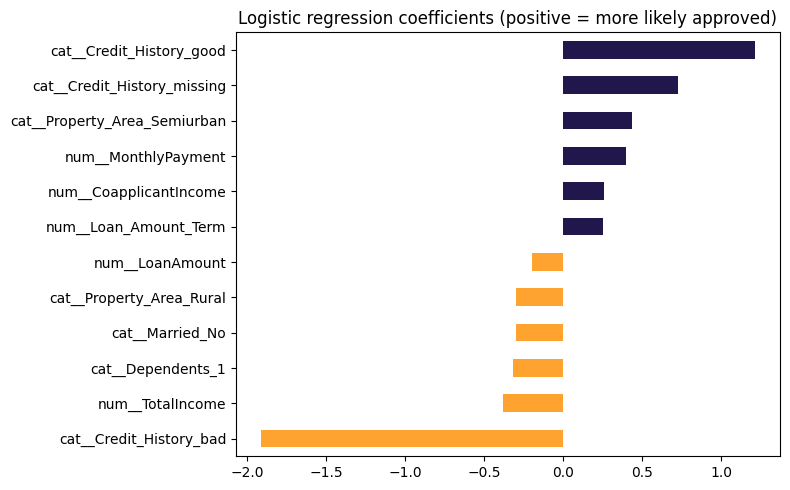

In [9]:
feature_names = final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final.named_steps["model"].coef_[0], index=feature_names).sort_values()
top = pd.concat([coefs.head(6), coefs.tail(6)])
top.plot(kind="barh", figsize=(8, 5), color=["#FEA330" if v < 0 else "#22174D" for v in top])
plt.title("Logistic regression coefficients (positive = more likely approved)")
plt.tight_layout(); plt.show()

## 7. Predictions for the unlabelled applications

In [10]:
final.fit(X, y)   # refit on all labelled data before scoring new applications
X_new = test_unlabelled.drop(columns=["Loan_ID"])
out = pd.DataFrame({"Loan_ID": test_unlabelled["Loan_ID"],
                    "approval_probability": final.predict_proba(X_new)[:, 1].round(3)})
out["predicted_status"] = np.where(out["approval_probability"] >= 0.5, "Y", "N")
out.to_csv("loan_test_predictions.csv", index=False)
print(out["predicted_status"].value_counts())
out.head()

predicted_status
Y    307
N     60
Name: count, dtype: int64


,Loan_ID,approval_probability,predicted_status
0,LP001015,0.808,Y
1,LP001022,0.778,Y
2,LP001031,0.845,Y
3,LP001035,0.828,Y
4,LP001051,0.650,Y


## 8. Conclusions and limitations
- **Credit history is the deciding factor.** A one-line rule matches the ML models on accuracy; the models' main added value is a probability score for ranking applications.
- **Small data.** 614 labelled applications means results move by several points depending on the split: about 79% accuracy in cross-validation versus 85% on the 123-application test set. The cross-validation figure is the more reliable estimate.
- **Fairness check needed before real use.** Gender and marital status are in the data. In a real lending system these would need a fairness review, and possibly removal, before deployment.
- **Next step:** test whether dropping Gender and Married changes accuracy (if not, remove them), and tune the decision threshold to the lender's cost of a bad loan versus a lost customer.